In [1]:
import pandas as pd

df = pd.read_csv("../Dataset/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [3]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [4]:
df.duplicated

<bound method DataFrame.duplicated of      CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]>

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [7]:
df["Gender"].value_counts()

Gender
Female    112
Male       88
Name: count, dtype: int64

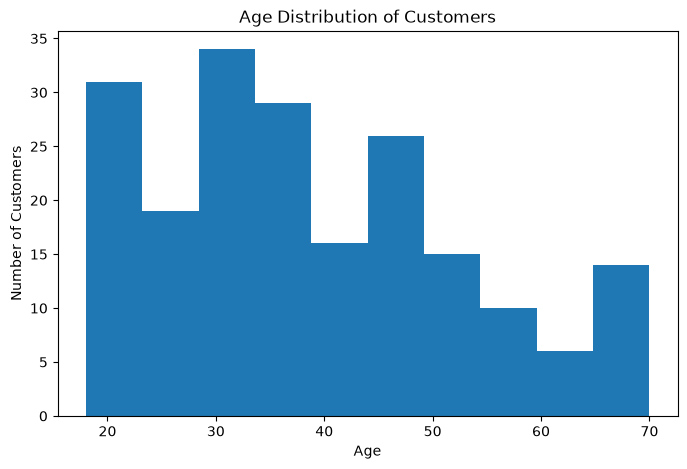

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df["Age"], bins=10)
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.title("Age Distribution of Customers")
plt.show()

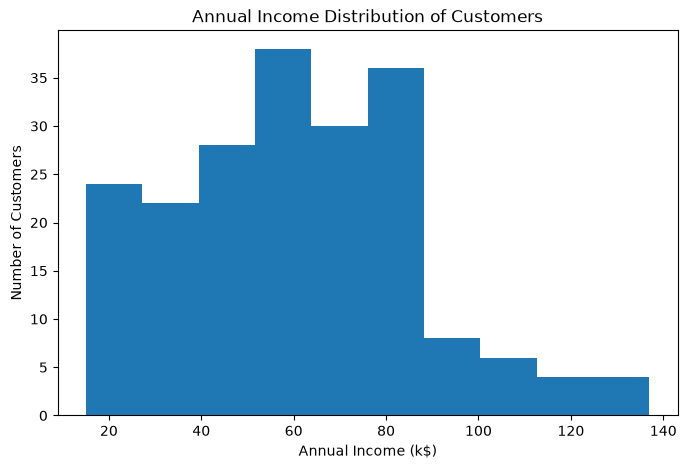

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["Annual Income (k$)"], bins=10)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.title("Annual Income Distribution of Customers")
plt.show()

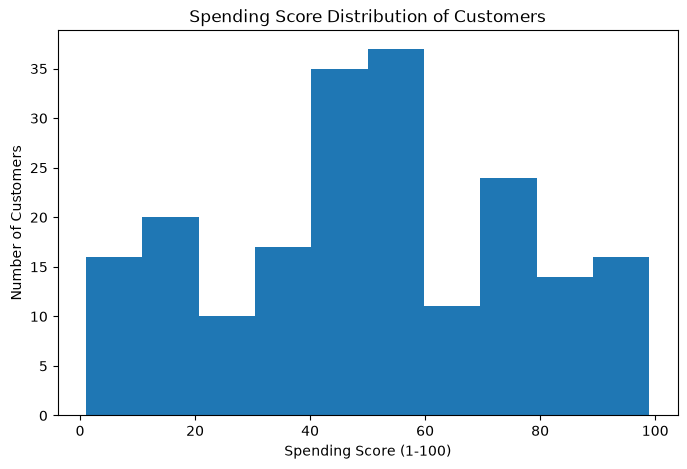

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["Spending Score (1-100)"], bins=10)
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.title("Spending Score Distribution of Customers")
plt.show()

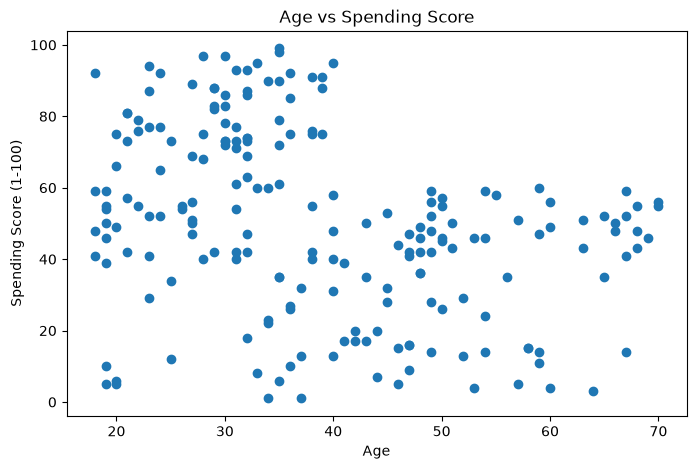

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["Spending Score (1-100)"])
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.title("Age vs Spending Score")
plt.show()

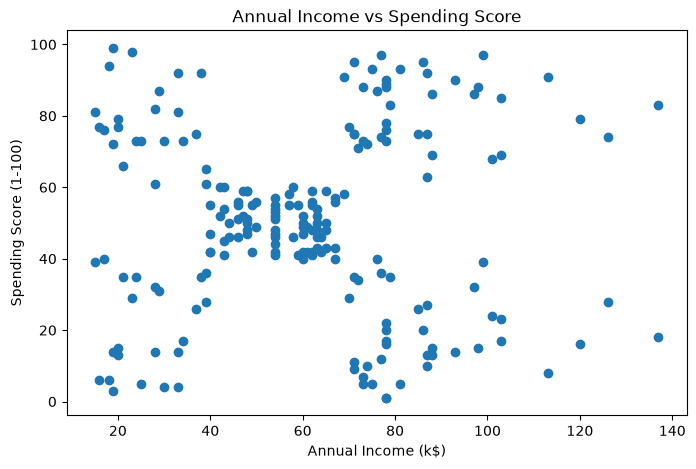

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Annual Income vs Spending Score")
plt.show()

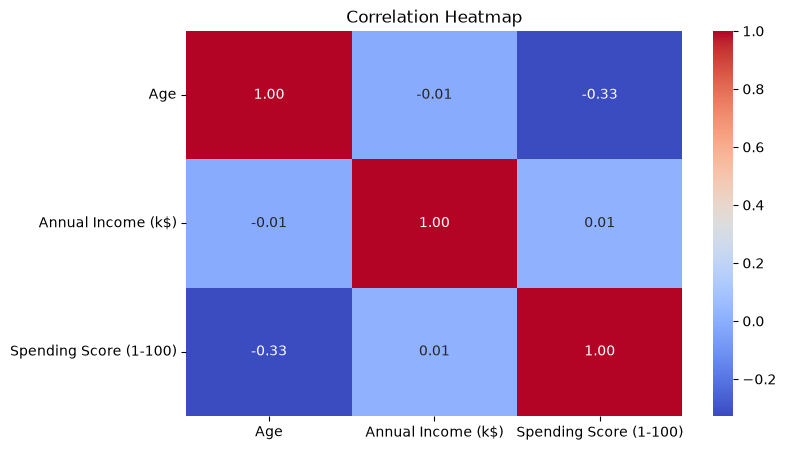

In [14]:
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.heatmap(
    df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [15]:
from sklearn.preprocessing import StandardScaler

features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

In [16]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

wcss

[600.0,
 389.3861889564372,
 295.2122461555489,
 205.22514747675916,
 168.24758017556837,
 133.86842085478855,
 117.01155455889811,
 103.87329152383712,
 93.09289110041726,
 82.385153645266]

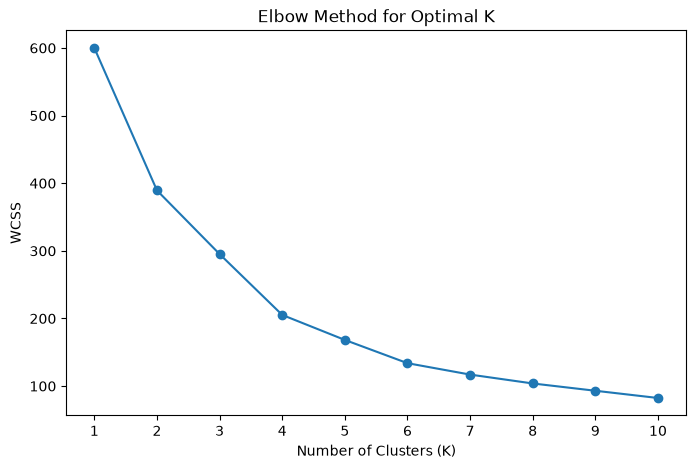

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.show()

In [18]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X_scaled)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,2
1,2,Male,21,15,81,2
2,3,Female,20,16,6,2
3,4,Female,23,16,77,2
4,5,Female,31,17,40,2


In [19]:
df["Cluster"].value_counts().sort_index()

Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

In [20]:
cluster_summary = df.groupby("Cluster")[[
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]].mean().round(2)

cluster_summary

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,53.98,47.71,39.97
1,32.88,86.10,81.53
2,25.44,40.00,60.30
3,39.37,86.50,19.58


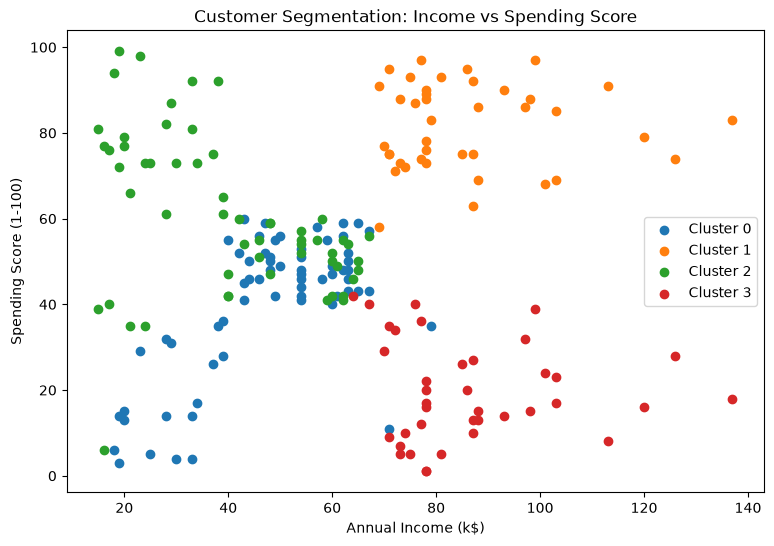

In [21]:
plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation: Income vs Spending Score")
plt.legend()
plt.show()

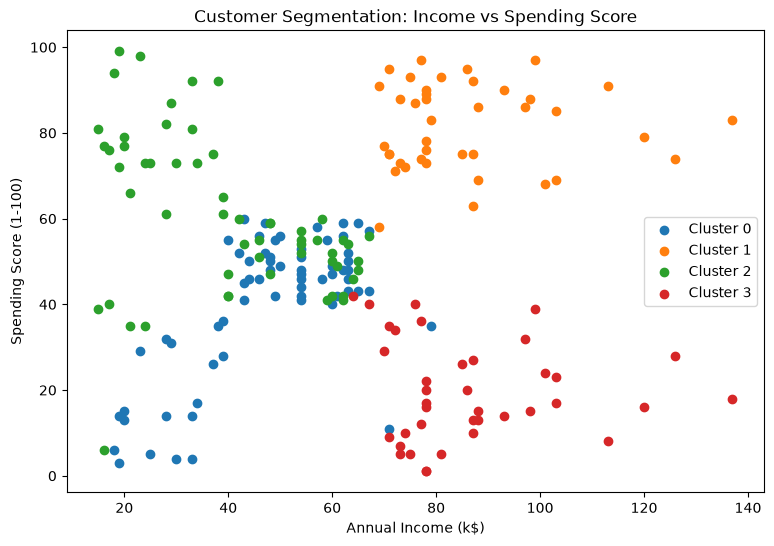

In [22]:
plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):
    cluster_data = df[df["Cluster"] == cluster]
    plt.scatter(
        cluster_data["Annual Income (k$)"],
        cluster_data["Spending Score (1-100)"],
        label=f"Cluster {cluster}"
    )

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation: Income vs Spending Score")
plt.legend()

plt.savefig("../Visualization/customer_segments.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
from sklearn.metrics import silhouette_score

silhouette_avg = silhouette_score(X_scaled, df["Cluster"])

print("Silhouette Score:", silhouette_avg)

Silhouette Score: 0.4039582785148566


In [24]:
pd.crosstab(df["Cluster"], df["Gender"])

Gender,Female,Male
Cluster,,
0,37,28
1,22,18
2,34,23
3,19,19


In [25]:
final_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

final_summary

,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Cluster,,,,
0,65,53.98,47.71,39.97
1,40,32.88,86.10,81.53
2,57,25.44,40.00,60.30
3,38,39.37,86.50,19.58


In [26]:
df.to_csv("../Dataset/Mall_Customers_Segmented.csv", index=False)

print("Segmented dataset saved successfully.")

Segmented dataset saved successfully.


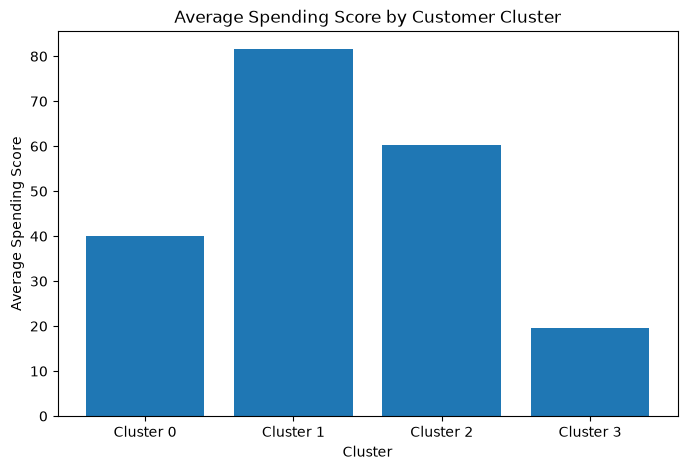

In [27]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_summary.index.astype(str),
    final_summary["Average_Spending_Score"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Spending Score")
plt.title("Average Spending Score by Customer Cluster")
plt.xticks(range(4), [f"Cluster {i}" for i in range(4)])
plt.show()

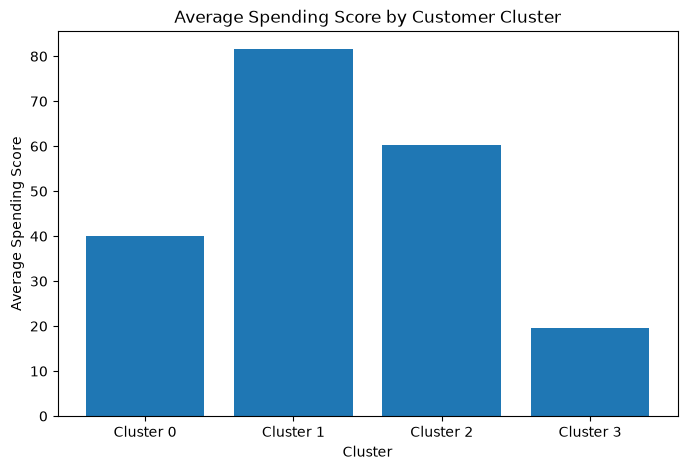

In [28]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_summary.index.astype(str),
    final_summary["Average_Spending_Score"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Spending Score")
plt.title("Average Spending Score by Customer Cluster")
plt.xticks(range(4), [f"Cluster {i}" for i in range(4)])

plt.savefig(
    "../Visualization/average_spending_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

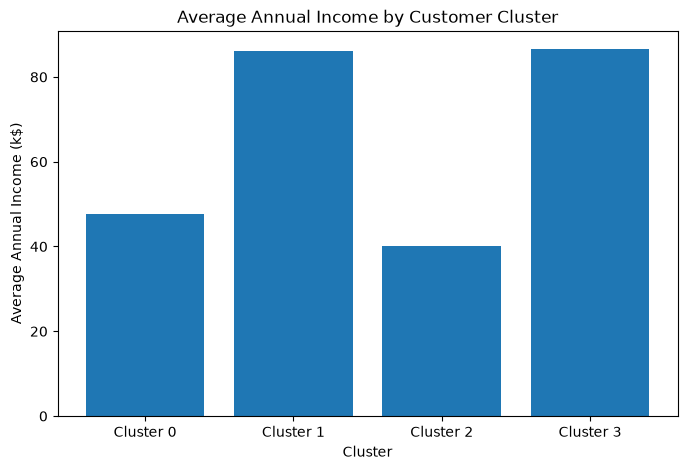

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    final_summary.index.astype(str),
    final_summary["Average_Income"]
)

plt.xlabel("Cluster")
plt.ylabel("Average Annual Income (k$)")
plt.title("Average Annual Income by Customer Cluster")
plt.xticks(range(4), [f"Cluster {i}" for i in range(4)])

plt.savefig(
    "../Visualization/average_income_by_cluster.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()